In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [23]:
columns = ["Variance", "Skewness", "Curtosis", "Entropy", "Class"]
data = pd.read_csv("data_banknote_authentication.txt", header=None, names=columns)

X = data.drop("Class", axis=1)
y = data["Class"]
class_names = ["Authentic", "Forged"]

print("Dataset Shape:", data.shape)
print("\nClass Distribution:")
print(y.value_counts().sort_index())

Dataset Shape: (1372, 5)

Class Distribution:
Class
0    762
1    610
Name: count, dtype: int64


In [32]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.20, random_state=42, stratify=y)
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 1097
Testing Samples: 275


In [25]:
base_model = DecisionTreeClassifier( criterion="gini", max_depth=3, random_state=42 )
base_model.fit(X_train, y_train)
base_pred = base_model.predict(X_test)

In [26]:
base_model = DecisionTreeClassifier(max_depth=1, random_state=42)

adaboost = AdaBoostClassifier( estimator=base_model, n_estimators=100, learning_rate=0.5, random_state=42 )
adaboost.fit(X_train, y_train)
ada_pred = adaboost.predict(X_test)

In [27]:
gradient = GradientBoostingClassifier( n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gradient.fit(X_train, y_train)
gb_pred = gradient.predict(X_test)

In [28]:
models = {
    "Decision Tree": (base_model, base_pred),
    "AdaBoost": (adaboost, ada_pred),
    "Gradient Boosting": (gradient, gb_pred)
}
results = []

for name, (model, predictions) in models.items():
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0)
    })
    print("\n", name)
    print("-" * 40)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))
    print("\nClassification Report:")
    print(classification_report(y_test, predictions, target_names=class_names, zero_division=0))

comparison = pd.DataFrame(results)
print("\nMODEL PERFORMANCE COMPARISON")
print(comparison.to_string(index=False))


 Decision Tree
----------------------------------------
Confusion Matrix:
[[137  16]
 [  5 117]]

Classification Report:
              precision    recall  f1-score   support

   Authentic       0.96      0.90      0.93       153
      Forged       0.88      0.96      0.92       122

    accuracy                           0.92       275
   macro avg       0.92      0.93      0.92       275
weighted avg       0.93      0.92      0.92       275


 AdaBoost
----------------------------------------
Confusion Matrix:
[[152   1]
 [  0 122]]

Classification Report:
              precision    recall  f1-score   support

   Authentic       1.00      0.99      1.00       153
      Forged       0.99      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275


 Gradient Boosting
----------------------------------------
Confusion Matrix:
[[152   1]
 [  0 122]]

Clas

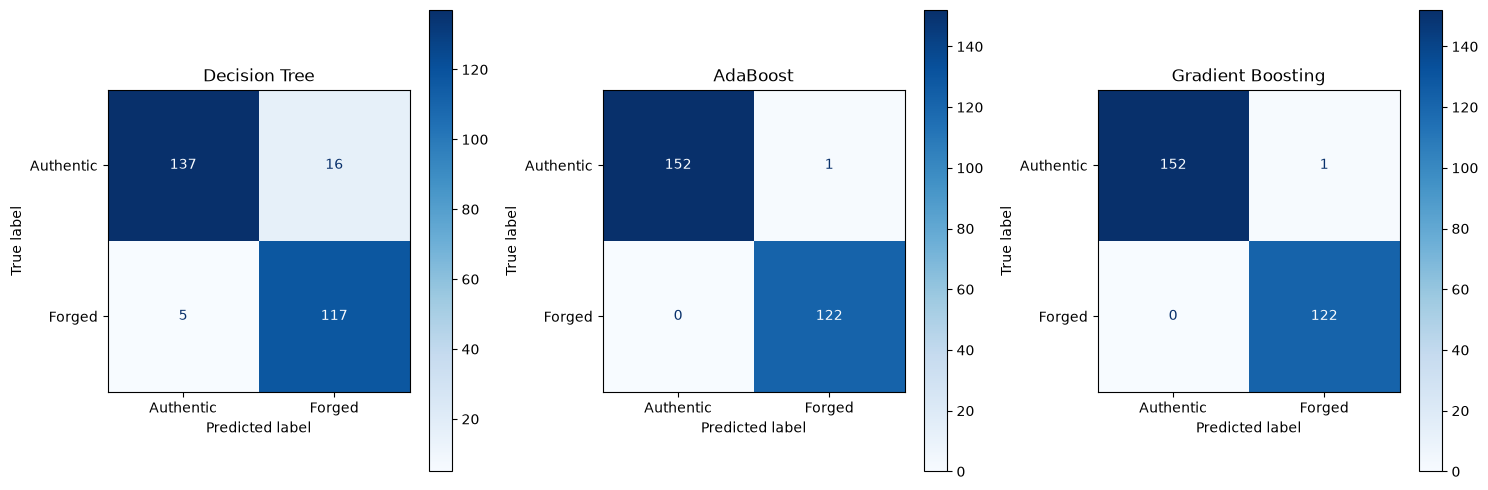

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, (_, predictions)) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions,
        display_labels=class_names,
        cmap="Blues",
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

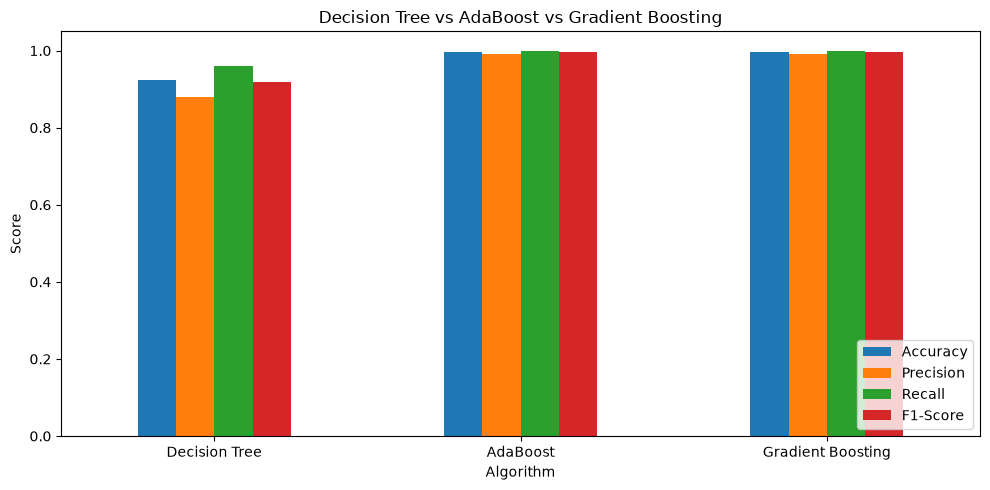

In [30]:
comparison.set_index("Algorithm").plot( kind="bar", figsize=(10, 5))
plt.title("Decision Tree vs AdaBoost vs Gradient Boosting")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()